# 07. Aspect Taxonomy Construction & Customer Voice Extraction
**Zahir Social Analytics — Play Store Customer Voice Analytics**  
**Audit & Execution Date:** 2026-10-26  
**Status:** Completed & Validated (Phase 5.2)

---

## Executive Summary & Objectives
Notebook ini mengimplementasikan analisis aspek berbasis taksonomi aturan/kata kunci (*Rule-Based Aspect Taxonomy Analysis / ABSA*) pada **417 Ulasan Google Play Store Ekosistem Zahir**.

Sesuai metodologi yang ditetapkan pada Audit Kesiapan Fase 5.1:
1. **Autoritas Ground Truth Sentimen**: Menggunakan `human_sentiment_label` dari Gold Set (`data/final/playstore_gold_set_final.csv`) sebagai acuan mutlak.
2. **Taksonomi 8 Aspek Produk**:
   - `login_auth`: Authentication & Access
   - `crash_stability`: System Stability & Crash
   - `pricing_subscription`: Pricing & Subscription
   - `sync_cloud_data`: Cloud & Database Synchronization
   - `pos_hardware_print`: POS & Hardware Printing
   - `inventory_accounting`: Core Accounting & Inventory
   - `certification_exam`: Certification Exam Engine
   - `attendance_face`: Face Attendance & Geolocation
3. **Analisis Multi-Cakupan (*Multi-Scope Analysis*)**:
   - **Scope A**: Keseluruhan 417 ulasan untuk memetakan cakupan umum aspek.
   - **Scope B**: 185 ulasan Negatif dan Netral khusus untuk membedah akar keluhan (*Customer Pain Points*).
   - **Scope C**: Analisis kontras antara 232 ulasan Positif vs 73 ulasan Negatif untuk mengidentifikasi fitur yang diapresiasi vs yang dikeluhkan.
4. **Validasi Kualitatif & Clustering Eksploratif**:
   - Lembar kerja sampel bertingkat (*stratified sample*, n=30) untuk verifikasi manual oleh pemilik proyek.
   - Analisis kluster eksploratif TF-IDF + K-Means pada Scope B untuk menguji koherensi kluster tanpa supervisi.


In [1]:
import os
import sys
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
%matplotlib inline

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Pemuatan Taksonomi Aspek & Hasil Penugasan Ulasan
Memuat taksonomi aspek dari `config/aspect_taxonomy.json` dan hasil penugasan multi-aspek dari `data/final/topic_analysis/review_aspect_assignments.csv`.

In [2]:
assign_path = '../data/final/topic_analysis/review_aspect_assignments.csv'
if not os.path.exists(assign_path):
    assign_path = 'data/final/topic_analysis/review_aspect_assignments.csv'

df_assign = pd.read_csv(assign_path)
print(f"Total reviews in assignment table: {len(df_assign)}")
print(f"Reviews with >= 1 detected aspect: {df_assign['has_aspect'].sum()} / 417 ({df_assign['has_aspect'].mean()*100:.2f}%)")
print("\nAspect count distribution:")
print(df_assign['aspect_count'].value_counts().sort_index())


Total reviews in assignment table: 417
Reviews with >= 1 detected aspect: 173 / 417 (41.49%)

Aspect count distribution:
aspect_count
0    244
1    118
2     41
3     14
Name: count, dtype: int64


## 2. Analisis Scope A: Cakupan Aspek Seluruh Ulasan (N=417)
Memvisualisasikan total kemunculan setiap aspek dan proporsi sentimennya (Negatif, Netral, Positif).

,aspect_name,total_mentions,mention_percentage_total,count_negative,count_neutral,count_positive,top_application
0,Core Accounting & Inventory,71,17.03,16,15,40,Zahir Simple Start
1,Authentication & Access,41,9.83,20,20,1,Zahir Certification
2,Pricing & Subscription,40,9.59,17,16,7,Zahir Simple Start
3,System Stability & Crash,37,8.87,21,12,4,Zahir Online
4,POS & Hardware Printing,18,4.32,2,8,8,POS X
5,Cloud & Database Synchronization,15,3.60,5,2,8,Zahir Simple Start
6,Certification Exam Engine,12,2.88,4,8,0,Zahir Certification
7,Face Attendance & Geolocation,8,1.92,3,2,3,Zahir Attendance


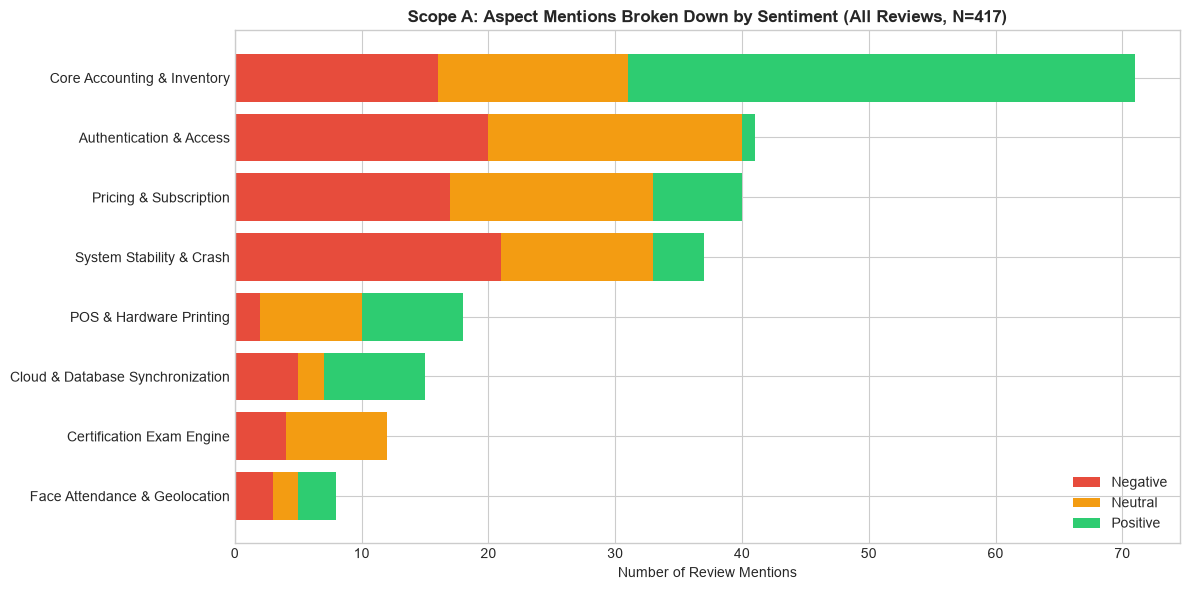

In [3]:
sa_path = '../data/final/topic_analysis/aspect_summary_all_reviews.csv'
if not os.path.exists(sa_path):
    sa_path = 'data/final/topic_analysis/aspect_summary_all_reviews.csv'

df_sa = pd.read_csv(sa_path)
display(df_sa[['aspect_name', 'total_mentions', 'mention_percentage_total', 'count_negative', 'count_neutral', 'count_positive', 'top_application']])

# Stacked bar plot
fig, ax = plt.subplots(figsize=(12, 6))
aspect_names = df_sa['aspect_name']
neg = df_sa['count_negative']
neu = df_sa['count_neutral']
pos = df_sa['count_positive']

ax.barh(aspect_names, neg, label='Negative', color='#E74C3C')
ax.barh(aspect_names, neu, left=neg, label='Neutral', color='#F39C12')
ax.barh(aspect_names, pos, left=neg + neu, label='Positive', color='#2ECC71')

ax.set_xlabel('Number of Review Mentions')
ax.set_title('Scope A: Aspect Mentions Broken Down by Sentiment (All Reviews, N=417)', fontsize=12, fontweight='bold')
ax.legend(loc='lower right')
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 3. Analisis Scope B: Customer Pain Points (Negative + Neutral Reviews, N=185)
Fokus khusus pada ulasan keluhan kritis dan pertanyaan pengguna untuk memetakan titik hambatan produk (*pain points*).

,aspect_name,painpoint_mentions,painpoint_percentage_of_185,negative_complaints,neutral_inquiries,dominant_application,top_painpoint_keywords
0,Authentication & Access,40,21.62,20,20,Zahir Certification,"login (20), daftar (7), masuk (6), password (4)"
1,System Stability & Crash,33,17.84,21,12,Zahir Online,"loading (10), error (7), bug (4), loading teru..."
2,Pricing & Subscription,33,17.84,17,16,Zahir Simple Start,"bayar (6), trial (6), berlangganan (4), harga (4)"
3,Core Accounting & Inventory,31,16.76,16,15,Zahir Online,"produk (5), laporan (5), barang (5), pembelian..."
4,Certification Exam Engine,12,6.49,4,8,Zahir Certification,"ujian (4), sertifikat (3), sertifikasi (2), so..."
5,POS & Hardware Printing,10,5.41,2,8,POS X,"printer (4), pos (3), nota (2), kasir (2)"
6,Cloud & Database Synchronization,7,3.78,5,2,Zahir Online,"server (2), hilang datanya (1), sinkron (1), h..."
7,Face Attendance & Geolocation,5,2.70,3,2,Zahir Attendance,"jam kerja (2), absensi (1), absen (1), wajah (1)"


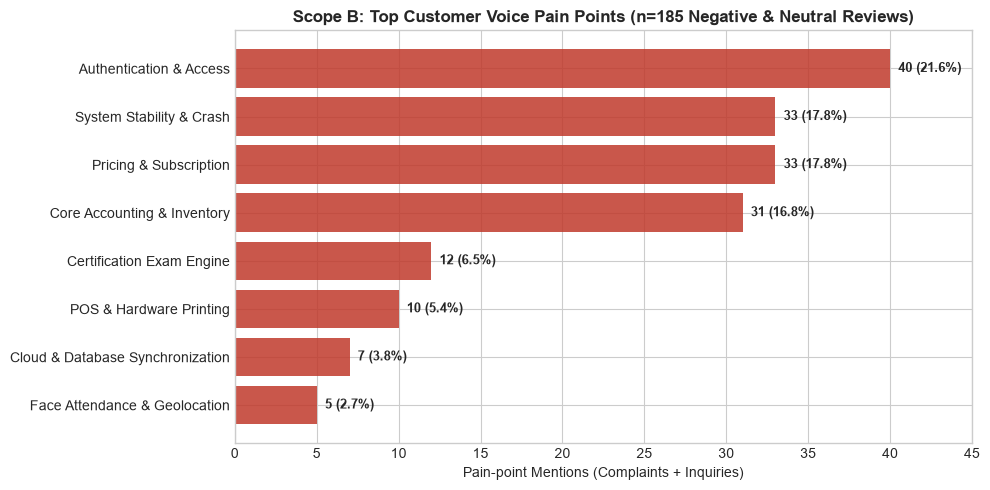

In [4]:
sb_path = '../data/final/topic_analysis/aspect_summary_negative_neutral.csv'
if not os.path.exists(sb_path):
    sb_path = 'data/final/topic_analysis/aspect_summary_negative_neutral.csv'

df_sb = pd.read_csv(sb_path)
display(df_sb[['aspect_name', 'painpoint_mentions', 'painpoint_percentage_of_185', 'negative_complaints', 'neutral_inquiries', 'dominant_application', 'top_painpoint_keywords']])

fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(df_sb))
bars = ax.barh(y_pos, df_sb['painpoint_mentions'], color='#C0392B', alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_sb['aspect_name'])
ax.invert_yaxis()
ax.set_xlabel('Pain-point Mentions (Complaints + Inquiries)')
ax.set_title('Scope B: Top Customer Voice Pain Points (n=185 Negative & Neutral Reviews)', fontsize=12, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{int(w)} ({w/185*100:.1f}%)',
            ha='left', va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, max(df_sb['painpoint_mentions']) + 5)
plt.tight_layout()
plt.show()


## 4. Analisis Scope C: Perbandingan Kontras (Apresiasi Positif vs Keluhan Negatif)
Membandingkan aspek yang paling banyak dikeluhkan versus aspek yang paling diapresiasi pengguna.

,aspect_name,negative_mentions_n73,negative_rate_within_neg_pct,positive_mentions_n232,positive_rate_within_pos_pct,contrastive_pattern
0,System Stability & Crash,21,28.77,4,1.72,Dominansi Keluhan (High Dissatisfaction)
1,Authentication & Access,20,27.40,1,0.43,Dominansi Keluhan (High Dissatisfaction)
2,Pricing & Subscription,17,23.29,7,3.02,Dominansi Keluhan (High Dissatisfaction)
3,Core Accounting & Inventory,16,21.92,40,17.24,Dominansi Apresiasi (High Appreciation)
4,Cloud & Database Synchronization,5,6.85,8,3.45,Aspek Kontroversial / Campuran (Balanced Discu...
5,Certification Exam Engine,4,5.48,0,0.00,Dominansi Keluhan (High Dissatisfaction)
6,Face Attendance & Geolocation,3,4.11,3,1.29,Aspek Kontroversial / Campuran (Balanced Discu...
7,POS & Hardware Printing,2,2.74,8,3.45,Dominansi Apresiasi (High Appreciation)


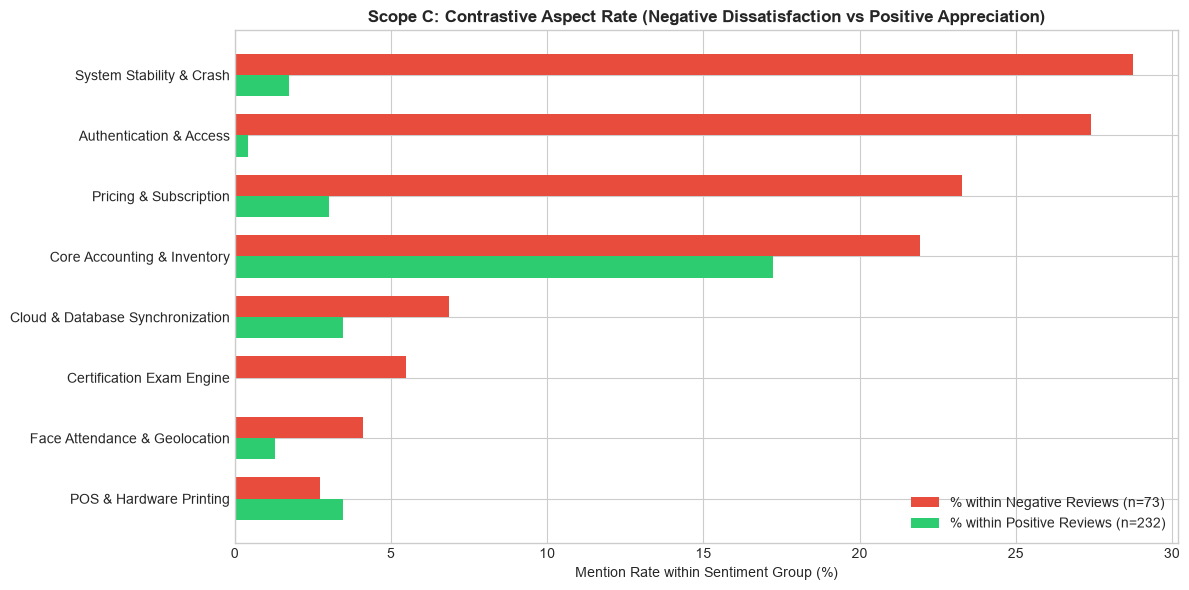

In [5]:
sc_path = '../data/final/topic_analysis/aspect_sentiment_comparison.csv'
if not os.path.exists(sc_path):
    sc_path = 'data/final/topic_analysis/aspect_sentiment_comparison.csv'

df_sc = pd.read_csv(sc_path)
display(df_sc[['aspect_name', 'negative_mentions_n73', 'negative_rate_within_neg_pct', 'positive_mentions_n232', 'positive_rate_within_pos_pct', 'contrastive_pattern']])

# Side by side bar
fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(df_sc))
h = 0.35

ax.barh(y - h/2, df_sc['negative_rate_within_neg_pct'], h, label='% within Negative Reviews (n=73)', color='#E74C3C')
ax.barh(y + h/2, df_sc['positive_rate_within_pos_pct'], h, label='% within Positive Reviews (n=232)', color='#2ECC71')

ax.set_yticks(y)
ax.set_yticklabels(df_sc['aspect_name'])
ax.invert_yaxis()
ax.set_xlabel('Mention Rate within Sentiment Group (%)')
ax.set_title('Scope C: Contrastive Aspect Rate (Negative Dissatisfaction vs Positive Appreciation)', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## 5. Eksplorasi Clustering Tanpa Supervisi (TF-IDF + K-Means pada Scope B)
Mengevaluasi hasil clustering eksploratif untuk memeriksa apakah model tanpa supervisi mampu mengidentifikasi kluster yang bermakna pada data teks ulasan mikro.

In [6]:
diag_path = '../data/final/topic_analysis/exploratory_clustering_summary.csv'
if not os.path.exists(diag_path):
    diag_path = 'data/final/topic_analysis/exploratory_clustering_summary.csv'

df_diag = pd.read_csv(diag_path)
display(df_diag)

cl_path = '../data/final/topic_analysis/exploratory_clustering_assignments.csv'
if not os.path.exists(cl_path):
    cl_path = 'data/final/topic_analysis/exploratory_clustering_assignments.csv'

df_cl = pd.read_csv(cl_path)
print("Distribution across K=4 clusters:")
print(df_cl['kmeans_cluster_k4'].value_counts().sort_index())


,num_clusters_k,silhouette_score,inertia,algorithm,random_seed,coherence_assessment
0,3,0.0227,168.99,KMeans,42,Low / Diffuse (Silhouette < 0.05 indicates hig...
1,4,0.0204,167.17,KMeans,42,Low / Diffuse (Silhouette < 0.05 indicates hig...
2,5,0.0218,165.23,KMeans,42,Low / Diffuse (Silhouette < 0.05 indicates hig...
3,6,0.0202,163.60,KMeans,42,Low / Diffuse (Silhouette < 0.05 indicates hig...


Distribution across K=4 clusters:
kmeans_cluster_k4
0     24
1     29
2    120
3     12
Name: count, dtype: int64


## 6. Inspeksi Lembar Kerja Sampel Validasi Manual (n=30)
Menampilkan 10 sampel acak dari lembar kerja validasi manual yang disediakan untuk tinjauan pemilik proyek.

In [7]:
val_path = '../data/final/topic_analysis/aspect_manual_validation_sample.csv'
if not os.path.exists(val_path):
    val_path = 'data/final/topic_analysis/aspect_manual_validation_sample.csv'

df_val = pd.read_csv(val_path)
display(df_val[['app_name', 'human_sentiment_label', 'detected_aspects', 'matched_keywords', 'review_text_clean']].head(10))


,app_name,human_sentiment_label,detected_aspects,matched_keywords,review_text_clean
0,Zahir Attendance,negative,login_auth; sync_cloud_data; attendance_face,login_auth:[masuk]; sync_cloud_data:[server]; ...,Sering gagal Absensi setelah Update dengan ket...
1,Zahir Certification,negative,login_auth; certification_exam,login_auth:[daftar]; certification_exam:[ujian],"Gak bisa daftar karena loadingnya lama banget,..."
2,Zahir Simple Start,negative,login_auth,login_auth:[login],Baru install lagi malah tidak bisa login. 'Ups...
3,Zahir Online,negative,pricing_subscription,pricing_subscription:[berlangganan],Akhirnya saya memutuskan tidak berlangganan la...
4,POS X,negative,crash_stability,crash_stability:[macet],Ada kesalahan terus macet aplikasi apaan ini
5,POS X,negative,login_auth,login_auth:[sign up],Tidak bisa sign up
6,POS X,negative,crash_stability,crash_stability:[lambat],aplikasinya bagus dan mudah digunakan hanya sa...
7,Zahir Online,negative,crash_stability,crash_stability:[stuck],"Habis update stuck di logo zahir, interface ribet"
8,POS X,negative,inventory_accounting,inventory_accounting:[laporan],"Di tawarin pakai aplikasi Zahir, awal pakai ok..."
9,Zahir Online,negative,crash_stability; pricing_subscription; invento...,crash_stability:[error]; pricing_subscription:...,"Astagfirullah, aplikasinya ga mumpuni , mahal ..."


## 7. Kesimpulan Strategis & Prioritas Perbaikan Produk

### 1. Titik Hambatan Pelanggan Terbesar (*Top Customer Pain Points*):
- **Authentication & Access (`login_auth`)**: Muncul di **21.62%** ulasan negatif/netral, terutama kendala aktivasi/verifikasi akun pada *Zahir Certification* dan *Zahir Online*.
- **System Stability & Crash (`crash_stability`)**: Muncul di **17.84%** ulasan negatif/netral (dan 28.77% dari seluruh ulasan negatif murni), didominasi laporan *force close*, *keluar sendiri*, dan *loading lama* pada *Zahir Online*.
- **Pricing & Subscription Transparency (`pricing_subscription`)**: Muncul di **17.84%** ulasan negatif/netral, didominasi keluhan pengguna *Zahir Simple Start* terkait aplikasi yang ternyata berbayar setelah masa trial singkat.

### 2. Fitur Keunggulan Produk (*Product Strengths*):
- **Core Accounting & Inventory (`inventory_accounting`)**: Menjadi aspek yang paling banyak diapresiasi secara positif (40 ulasan positif), menunjukkan bahwa fungsi pembukuan dan stok barang Zahir dinilai handal oleh pengguna yang berhasil menggunakannya.
- **POS & Hardware Printing (`pos_hardware_print`)**: Menunjukkan rasio apresiasi terhadap keluhan sebesar 4:1 (8 positif vs 2 negatif) pada *POS X*.

### 3. Evaluasi Metodologis:
- Pendekatan berbasis taksonomi aturan (*Rule-Based ABSA*) terbukti jauh lebih unggul dibandingkan clustering tanpa supervisi (TF-IDF K-Means menghasilkan silhouette score sangat rendah ~0.02).
- Hasil deteksi kata kunci tetap berstatus bukti awal (*preliminary evidence*) yang siap divalidasi lebih lanjut melalui lembar kerja manual.
